#Importing neccessary Libraries

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

#Loading the Data

In [61]:
filepath='/content/sample_data/quickkart_customers.csv'
cart=pd.read_csv(filepath)
cart.shape

(1500, 10)

In [62]:
cart.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0


#EDA

In [63]:
cart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1500 non-null   object 
 1   Age               1419 non-null   float64
 2   Gender            1449 non-null   object 
 3   City              1434 non-null   object 
 4   Membership        1500 non-null   object 
 5   Payment_Mode      1405 non-null   object 
 6   Monthly_Income    1346 non-null   float64
 7   Orders_Last_Year  1500 non-null   float64
 8   Avg_Order_Value   1376 non-null   float64
 9   Total_Spent       1500 non-null   float64
dtypes: float64(5), object(5)
memory usage: 117.3+ KB


In [64]:
cart.isna().sum()

,0
Customer_ID,0
Age,81
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [65]:
cart['Gender'].value_counts()

,count
Gender,
Female,727
Male,674
Other,38
F,7
M,3


In [66]:
cart.describe()

,Age,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
count,1419.000000,1346.000000,1500.000000,1376.000000,1500.000000
mean,34.248062,43418.424963,8.986667,817.260901,5723.821333
std,10.554268,62967.813712,15.567661,1805.319096,6497.750986
min,-3.000000,5500.000000,1.000000,81.000000,157.000000
25%,27.000000,24100.000000,4.000000,401.000000,1937.750000
50%,34.000000,33600.000000,7.000000,579.500000,3820.500000
75%,41.000000,47300.000000,11.000000,868.250000,7280.250000
max,150.000000,900000.000000,310.000000,35000.000000,85073.000000


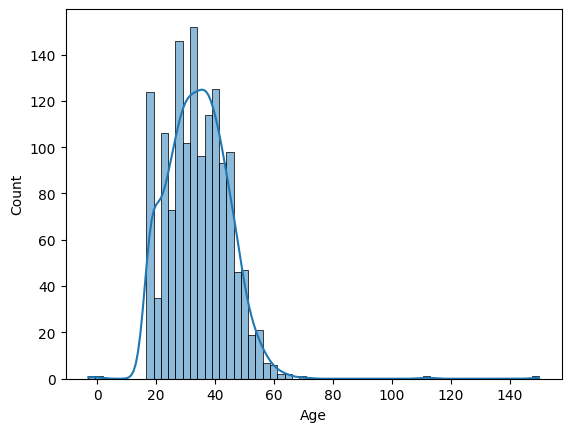

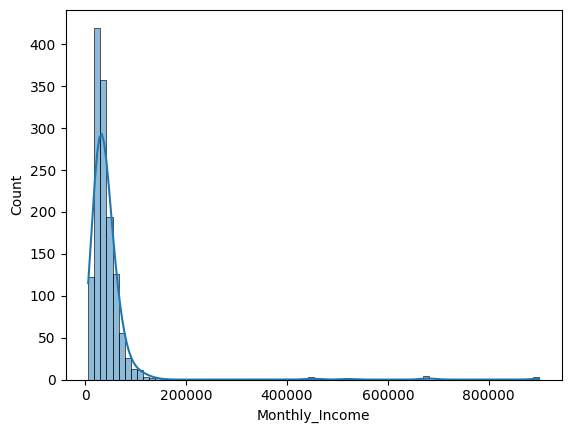

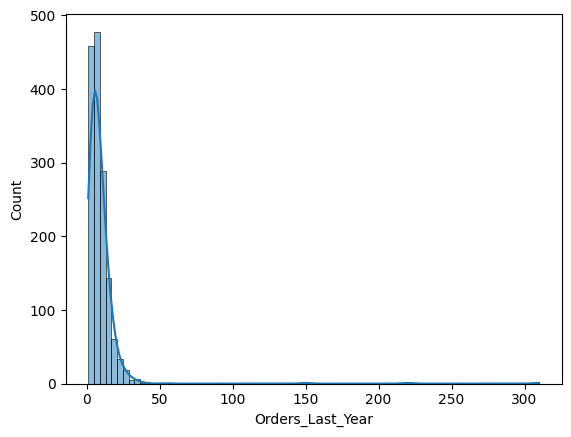

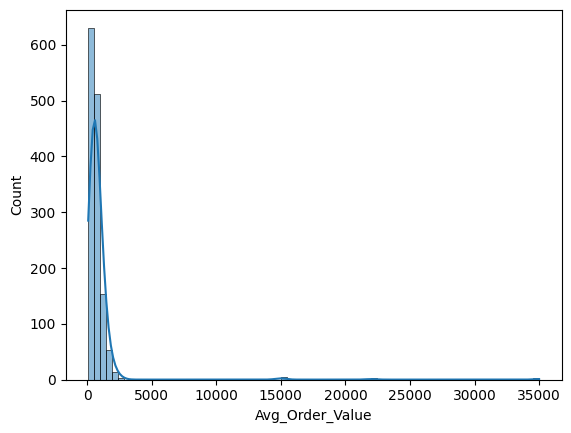

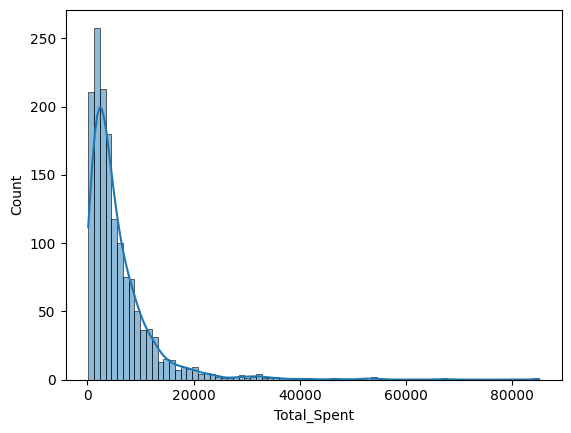

In [67]:
sns.histplot(data=cart,x="Age",kde=True)
plt.show()
sns.histplot(data=cart,x="Monthly_Income",kde=True)
plt.show()
sns.histplot(data=cart,x="Orders_Last_Year",kde=True)
plt.show()
sns.histplot(data=cart,x="Avg_Order_Value",kde=True)
plt.show()
sns.histplot(data=cart,x="Total_Spent",kde=True)
plt.show()

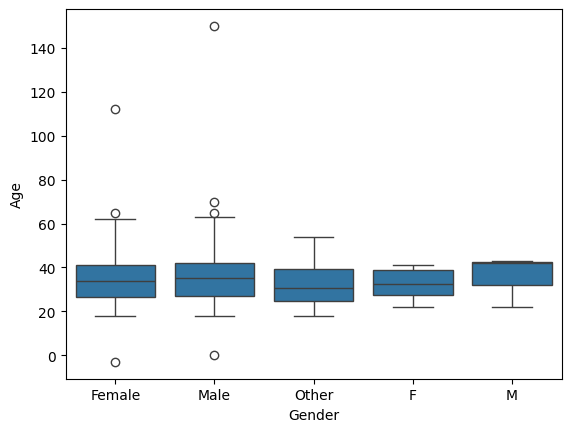

In [68]:
sns.boxplot(data=cart,x='Gender',y='Age')
plt.show()

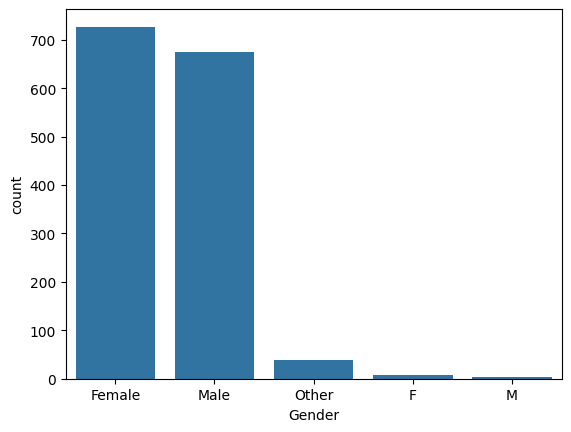

In [69]:
sns.countplot(data=cart,x='Gender')
plt.show()

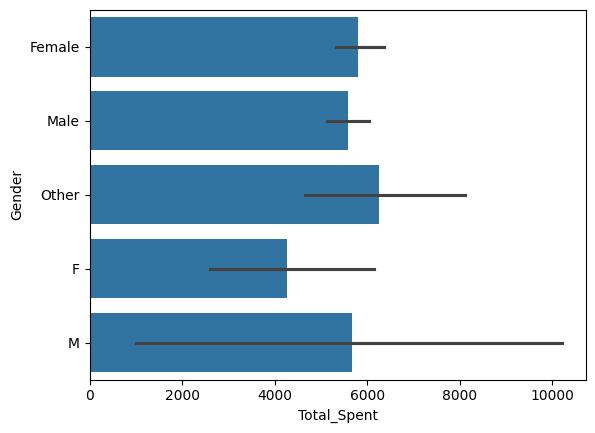

In [70]:
sns.barplot(y=cart["Gender"],x=cart["Total_Spent"])
plt.show()

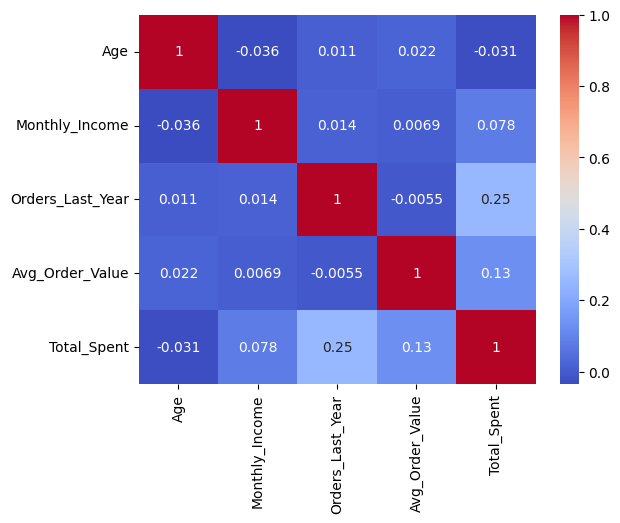

In [71]:
corr=cart.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

#Data Cleaning

##Numerical value handling

###1.Null value Handling

In [72]:
num_cols=cart.select_dtypes(include='number').columns
cat_cols=cart.select_dtypes(include='object').columns

In [73]:
cart[num_cols].isna().sum()

,0
Age,81
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [74]:
(cart[num_cols].isna().sum()/len(cart))*100

,0
Age,5.400000
Monthly_Income,10.266667
Orders_Last_Year,0.000000
Avg_Order_Value,8.266667
Total_Spent,0.000000


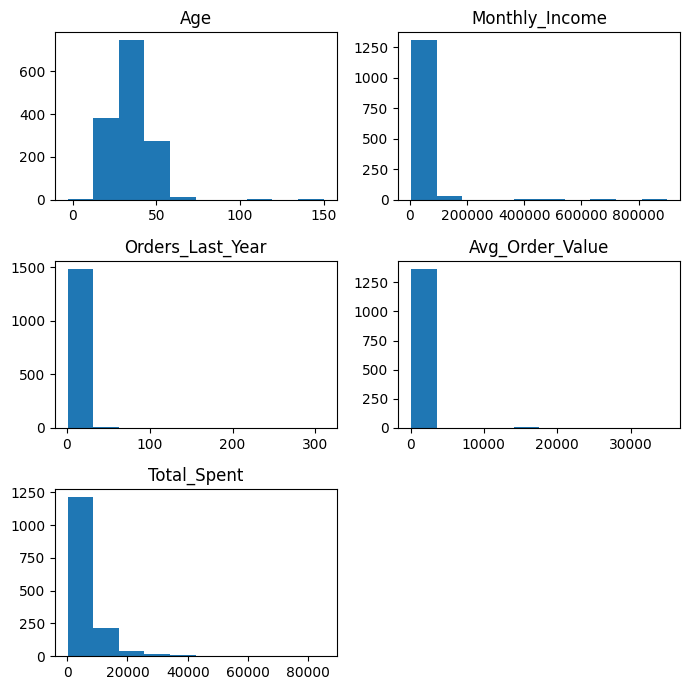

In [75]:
plt.figure(figsize=(7,7))
for i,col in enumerate(num_cols,1):
  plt.subplot(3,2,i)
  plt.hist(cart[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [76]:
cart.select_dtypes(include='number').isna().sum()

,0
Age,81
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [77]:
cart['Age']=cart['Age'].fillna(cart['Age'].median())
cart['Monthly_Income']=cart['Monthly_Income'].fillna(cart['Monthly_Income'].median())
cart['Avg_Order_Value']=cart['Avg_Order_Value'].fillna(cart['Avg_Order_Value'].median())

In [78]:
cart.select_dtypes(include='number').isna().sum()

,0
Age,0
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0


###2.Outlier Handling

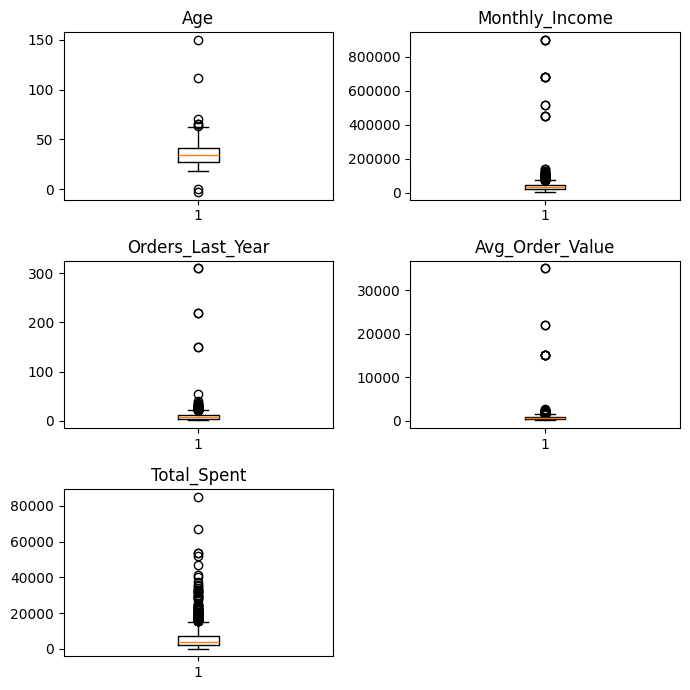

In [79]:
plt.figure(figsize=(7,7))
for i,col in enumerate(num_cols,1):
  plt.subplot(3,2,i)
  plt.boxplot(cart[col])
  plt.title(col)
  plt.tight_layout()
plt.show()

In [80]:
Q1=cart[num_cols].quantile(.25)
Q3=cart[num_cols].quantile(.75)
IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR

cart[num_cols]=cart[num_cols].clip(lower=lower_limit,upper=upper_limit,axis=1)

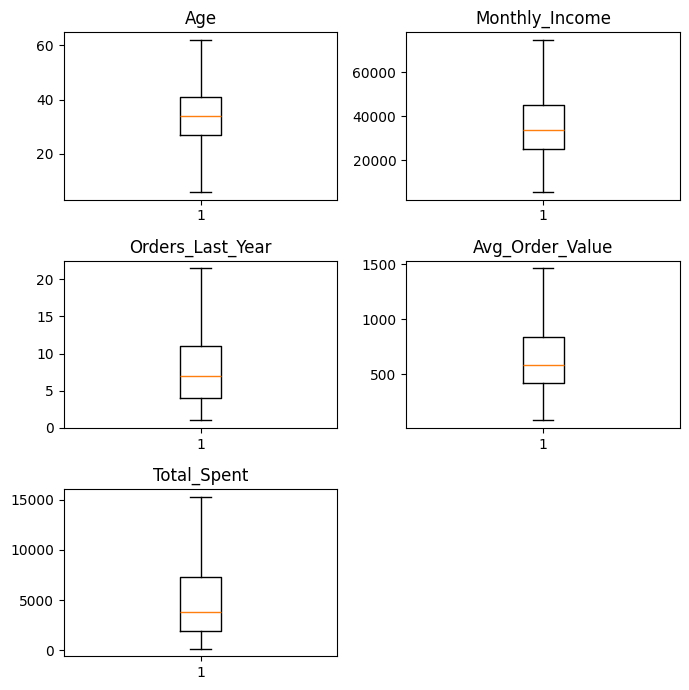

In [81]:
plt.figure(figsize=(7,7))
for i,col in enumerate(num_cols,1):
  plt.subplot(3,2,i)
  plt.boxplot(cart[col])
  plt.title(col)
  plt.tight_layout()
plt.show()

###3.Duplicate value removal

In [82]:
cart.duplicated().sum()

np.int64(35)

In [83]:
cart=cart.drop_duplicates().reset_index(drop=True)
cart.shape

(1465, 10)

In [84]:
cart.duplicated().sum()

np.int64(0)

###4.Scaling

In [85]:
scaler = StandardScaler()
cart[num_cols]=scaler.fit_transform(cart[num_cols])

In [86]:
print(cart[num_cols])

           Age  Monthly_Income  Orders_Last_Year  Avg_Order_Value  Total_Spent
0    -0.537494        1.187149         -0.370555        -0.415223    -0.479371
1     0.193541        0.689702          2.457345         0.572356     2.432144
2    -1.686262       -0.261665         -1.124661        -0.510411    -0.991180
3    -0.224193       -0.243010          0.760605         2.379819     2.432144
4    -0.015326        2.349932          0.383552        -0.703762    -0.294391
...        ...             ...               ...              ...          ...
1460 -1.686262        1.398564          0.195025        -0.519335    -0.194234
1461  0.193541        0.067894         -1.124661        -1.173755    -1.098526
1462 -1.059661        0.521814          0.572079        -0.795976    -0.222987
1463 -0.850794       -0.839947         -0.747608        -0.108835    -0.635118
1464 -1.164094       -0.367372          0.760605        -0.247156     1.437998

[1465 rows x 5 columns]


##Categorical value handling

In [87]:
cart.describe(include='object').T

,count,unique,top,freq
Customer_ID,1465,1465,C0258,1
Gender,1415,5,Female,715
City,1400,17,Kochi,351
Membership,1465,9,Basic,766
Payment_Mode,1372,5,UPI,595


In [88]:
for col in cat_cols:
  print(col,cart[col].unique())

Customer_ID ['C0258' 'C0758' 'C0993' ... 'C0639' 'C0349' 'C0383']
Gender ['Female' 'Male' 'Other' nan 'F' 'M']
City ['Kozhikode' 'Thrissur' 'Kochi' 'Kollam' 'kochi' 'Palakkad' 'Kannur' nan
 'Alappuzha' 'Trivandrum' 'Kochi ' 'Trivandrum ' 'TRIVANDRUM' 'kozhikode'
 'kollam' 'KOCHI' 'KOLLAM' 'thrissur']
Membership ['Basic' 'Silver' 'Gold' 'SILVER' 'Platinum' 'PLATINUM' 'silver' 'GOLD'
 'basic']
Payment_Mode ['Debit Card' 'UPI' 'Credit Card' 'Cash on Delivery' nan 'Net Banking']


In [89]:
for col in cat_cols:
  cart[col]=cart[col].str.strip().str.title()

In [90]:
for col in cat_cols:
  print(col,cart[col].unique())

Customer_ID ['C0258' 'C0758' 'C0993' ... 'C0639' 'C0349' 'C0383']
Gender ['Female' 'Male' 'Other' nan 'F' 'M']
City ['Kozhikode' 'Thrissur' 'Kochi' 'Kollam' 'Palakkad' 'Kannur' nan
 'Alappuzha' 'Trivandrum']
Membership ['Basic' 'Silver' 'Gold' 'Platinum']
Payment_Mode ['Debit Card' 'Upi' 'Credit Card' 'Cash On Delivery' nan 'Net Banking']


In [91]:
for col in cat_cols:
  print(col,cart[col].unique(),cart[col].nunique())

Customer_ID ['C0258' 'C0758' 'C0993' ... 'C0639' 'C0349' 'C0383'] 1465
Gender ['Female' 'Male' 'Other' nan 'F' 'M'] 5
City ['Kozhikode' 'Thrissur' 'Kochi' 'Kollam' 'Palakkad' 'Kannur' nan
 'Alappuzha' 'Trivandrum'] 8
Membership ['Basic' 'Silver' 'Gold' 'Platinum'] 4
Payment_Mode ['Debit Card' 'Upi' 'Credit Card' 'Cash On Delivery' nan 'Net Banking'] 5


In [92]:
cart['Gender'].value_counts()

,count
Gender,
Female,715
Male,654
Other,36
F,7
M,3


In [93]:
cart.loc[cart['Gender']=='F','Gender']='Female'
cart.loc[cart['Gender']=='M','Gender']='Male'

In [94]:
cart['Gender'].value_counts()

,count
Gender,
Female,722
Male,657
Other,36


###1.Null value handling

In [95]:
cart[cat_cols].isna().sum()

,0
Customer_ID,0
Gender,50
City,65
Membership,0
Payment_Mode,93


In [96]:
(cart[cat_cols].isna().sum()/len(cart))*100

,0
Customer_ID,0.000000
Gender,3.412969
City,4.436860
Membership,0.000000
Payment_Mode,6.348123


In [97]:
for col in ['Gender','City','Payment_Mode']:
  cart[col]=cart[col].fillna(cart[col].mode()[0])

In [98]:
cart[cat_cols].isna().sum()

,0
Customer_ID,0
Gender,0
City,0
Membership,0
Payment_Mode,0


###2.Encoding

In [99]:
label_encoder = LabelEncoder()
cart['Membership']=label_encoder.fit_transform(cart['Membership'])
cart.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,-0.537494,Female,Kozhikode,0,Debit Card,1.187149,-0.370555,-0.415223,-0.479371
1,C0758,0.193541,Male,Thrissur,3,Upi,0.689702,2.457345,0.572356,2.432144
2,C0993,-1.686262,Male,Thrissur,0,Upi,-0.261665,-1.124661,-0.510411,-0.991180
3,C1171,-0.224193,Female,Kochi,1,Credit Card,-0.243010,0.760605,2.379819,2.432144
4,C1069,-0.015326,Female,Kochi,1,Cash On Delivery,2.349932,0.383552,-0.703762,-0.294391


In [100]:
print(cat_cols)

Index(['Customer_ID', 'Gender', 'City', 'Membership', 'Payment_Mode'], dtype='object')


In [101]:
cart.drop(columns=['Customer_ID'],inplace=True)

In [102]:
cart.select_dtypes(include='object').columns

Index(['Gender', 'City', 'Payment_Mode'], dtype='object')

In [103]:
encoder_gender=OneHotEncoder()
encoded_data=encoder_gender.fit_transform(cart[['Gender']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_gender.get_feature_names_out(['Gender']),
    index=cart.index
)
cart=pd.concat([cart.drop('Gender',axis=1),encoded_df],axis=1)

In [104]:
encoder_city=OneHotEncoder()
encoded_data=encoder_city.fit_transform(cart[['City']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_city.get_feature_names_out(['City']),
    index=cart.index
)
cart=pd.concat([cart.drop('City',axis=1),encoded_df],axis=1)

In [105]:
encoder_payement=OneHotEncoder()
encoded_data=encoder_payement.fit_transform(cart[['Payment_Mode']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_payement.get_feature_names_out(['Payment_Mode']),
    index=cart.index
)
pd.concat([cart.drop('Payment_Mode',axis=1),encoded_df],axis=1)

,Age,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,City_Alappuzha,...,City_Kollam,City_Kozhikode,City_Palakkad,City_Thrissur,City_Trivandrum,Payment_Mode_Cash On Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_Upi
0,-0.537494,0,1.187149,-0.370555,-0.415223,-0.479371,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.193541,3,0.689702,2.457345,0.572356,2.432144,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.686262,0,-0.261665,-1.124661,-0.510411,-0.991180,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.224193,1,-0.243010,0.760605,2.379819,2.432144,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,-0.015326,1,2.349932,0.383552,-0.703762,-0.294391,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,-1.686262,1,1.398564,0.195025,-0.519335,-0.194234,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1461,0.193541,0,0.067894,-1.124661,-1.173755,-1.098526,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1462,-1.059661,0,0.521814,0.572079,-0.795976,-0.222987,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1463,-0.850794,0,-0.839947,-0.747608,-0.108835,-0.635118,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [106]:
cart

,Age,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,City_Alappuzha,City_Kannur,City_Kochi,City_Kollam,City_Kozhikode,City_Palakkad,City_Thrissur,City_Trivandrum
0,-0.537494,0,Debit Card,1.187149,-0.370555,-0.415223,-0.479371,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.193541,3,Upi,0.689702,2.457345,0.572356,2.432144,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-1.686262,0,Upi,-0.261665,-1.124661,-0.510411,-0.991180,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.224193,1,Credit Card,-0.243010,0.760605,2.379819,2.432144,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-0.015326,1,Cash On Delivery,2.349932,0.383552,-0.703762,-0.294391,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,-1.686262,1,Upi,1.398564,0.195025,-0.519335,-0.194234,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1461,0.193541,0,Cash On Delivery,0.067894,-1.124661,-1.173755,-1.098526,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1462,-1.059661,0,Upi,0.521814,0.572079,-0.795976,-0.222987,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1463,-0.850794,0,Upi,-0.839947,-0.747608,-0.108835,-0.635118,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [107]:
min_max_scalar = MinMaxScaler()
cart[num_cols]=min_max_scalar.fit_transform(cart[num_cols])
cart

,Age,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,City_Alappuzha,City_Kannur,City_Kochi,City_Kollam,City_Kozhikode,City_Palakkad,City_Thrissur,City_Trivandrum
0,0.410714,0,Debit Card,0.729378,0.243902,0.319913,0.197265,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.535714,3,Upi,0.613603,0.975610,0.560210,1.000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.214286,0,Upi,0.392185,0.048780,0.296752,0.056154,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.464286,1,Credit Card,0.396527,0.536585,1.000000,1.000000,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.500000,1,Cash On Delivery,1.000000,0.439024,0.249706,0.248266,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,0.214286,1,Upi,0.778582,0.390244,0.294581,0.275880,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1461,0.535714,0,Cash On Delivery,0.468886,0.048780,0.135348,0.026557,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1462,0.321429,0,Upi,0.574530,0.487805,0.227269,0.267953,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1463,0.357143,0,Upi,0.257598,0.146341,0.394463,0.154324,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
